# Thesis Outputs

Run `3_forecasts.ipynb` first to generate the forecast CSVs, then run this notebook top-to-bottom.

---
**All Tables and Figures are placed in the Appendix** (thesis guidelines). \
Cells are ordered to match the sequence in which each item is first discussed in my thesis.

In [1]:
# ============================================================
# IMPORTS & LOADS
# ============================================================

import sys, os
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from scipy.stats import jarque_bera, skew, kurtosis as sp_kurt  # Statistical diagnostics
from itertools import combinations                              # Combinatorial utilities
from config import *                                            # Global project configuration

# Forecast evaluation metrics
from src.evaluation.metrics import mse, qlike, mse_series, qlike_series
from src.evaluation.mcs import ModelConfidenceSet, block_length_for_horizon

HORIZONS = forecast_horizons
MODELS   = ['gjr', 'mf2', 'har', 'xgb', 'mlp', 'hybrid']
LABELS   = {
    'gjr': 'GJR-GARCH', 'mf2': 'MF2-GARCH', 'har': 'HAR-GARCH',
    'xgb': 'XGBoost',   'mlp': 'MLP',        'hybrid': 'Hybrid',
}

# File name mapping
FILE_TAGS = {
    'gjr': 'GJR', 'mf2': 'MF2', 'har': 'HAR',
    'xgb': 'XGB', 'mlp': 'MLP', 'hybrid': 'Hybrid',
}

# Consistent color palette
COLORS = ["#1f64a8", "#C7974F", '#4dac26', "#d61313", '#762a83', "#17becf"]

# Global plotting style
plt.rcParams.update({
    'font.size': 11,            # Base font size
    'axes.spines.top': False,   # Remove top border
    'axes.spines.right': False, # Remove right border
    'figure.dpi': 300,          # Export resolution
})

In [2]:
df_raw = pd.read_excel('../data/processed/rv_features_created.xlsx')
df_raw['date'] = pd.to_datetime(df_raw['date'])

# Identify dataset
def load_stock(stock):
    """Merge test-period actuals with all available forecast CSVs for one stock."""
    sdf  = df_raw[df_raw['symbol'] == stock]
    test = sdf[sdf['date'] >= split_date].copy().reset_index(drop=True)
    out  = test[['date', 'rv', 'target_rv_1', 'target_rv_5', 'target_rv_22']].copy()

    for key, tag in FILE_TAGS.items():
        path = f'{FORECAST_DIR}/{stock}_{tag}.csv'
        
        if os.path.exists(path):
            fcst = pd.read_csv(path, index_col=0).reset_index(drop=True)
            out  = pd.concat([out, fcst], axis=1)   # Concatenate both acutals and predicts 

  
    return out.dropna().reset_index(drop=True)

evals = {s: load_stock(s) for s in stocks}
sample = next(iter(evals.values()))

print(f"Stocks loaded      : {list(evals.keys())}")
print(f"Columns (first 8)  : {list(sample.columns[:8])} ...")

Stocks loaded      : ['MSFT', 'JNJ', 'PG', 'XOM', 'JPM', 'NVDA']
Columns (first 8)  : ['date', 'rv', 'target_rv_1', 'target_rv_5', 'target_rv_22', 'gjr_h1', 'gjr_h5', 'gjr_h22'] ...


In [3]:
# Identify models
available = [k for k in MODELS if f'{k}_h1' in next(iter(evals.values())).columns]
print(f'Available models: {[LABELS[k] for k in available]}')
print(f'Test obs per stock: {len(next(iter(evals.values())))}'  )

Available models: ['GJR-GARCH', 'MF2-GARCH', 'HAR-GARCH', 'XGBoost', 'MLP', 'Hybrid']
Test obs per stock: 1042


In [4]:
# ============================================================
# SHARED HELPERS
# ============================================================

def scalar_metrics(eval_df, h):
    """Return DataFrame of MSE/QLIKE for each available model at horizon h."""
    y = eval_df[f'target_rv_{h}'].values    # Extract actual values
    rows = []                               # Container for model evaluation results

    # Evaluate each available model
    for key in available:
        col = f'{key}_h{h}' # Forecast column corresponding to the current horizon
        
        # Skip models that do not have forecasts for this horizon
        if col in eval_df.columns:
            rows.append({'Model': LABELS[key],
                         'MSE':   mse(y, eval_df[col].values),
                         'QLIKE': qlike(y, eval_df[col].values)})
            
    return pd.DataFrame(rows)

def loss_series_df(eval_df, h, loss='qlike'):
    """Per-observation loss series for all available models at horizon h."""
    y  = eval_df[f'target_rv_{h}'].values
    fn = qlike_series if loss == 'qlike' else mse_series    # Select loss function

    # Construct loss matrix
    return pd.DataFrame({
        LABELS[key]: fn(y, eval_df[f'{key}_h{h}'].values)   # Computes the loss for every forecast date
        for key in available if f'{key}_h{h}' in eval_df.columns
    })

def plot_forecast_grid(h, filename, title):
    """6-panel actual-vs-forecast grid across all stocks for a given horizon."""
    fig, axes = plt.subplots(3, 2, figsize=(16, 11), sharex=False)
    axes = axes.flatten()

    for ax, stock in zip(axes, stocks):
        edf = evals[stock]
        ax.plot(edf['date'], edf[f'target_rv_{h}'] * 1e4,
                lw=0.9, color='black', label='Actual', zorder=6)
        
        for i, key in enumerate(available):
            ax.plot(edf['date'], edf[f'{key}_h{h}'] * 1e4,
                    lw=0.5, alpha=0.7, color=COLORS[i], label=LABELS[key])
            
        # Cap the y-axis at the actual RV range so occasional explosive GARCH
        # forecasts (e.g. a GJR-GARCH spike on NVDA) do not flatten the panel.
        # Forecasts above the cap are clipped; their magnitudes are in Tables 2/5.
        ax.set_ylim(0, float(edf[f'target_rv_{h}'].max()) * 1e4 * 1.3)

        ax.set_title(stock, fontsize=11, fontweight='bold')
        ax.set_ylabel(r'RV ($\times 10^{-4}$)')
        ax.grid(axis='y', alpha=0.3, ls='--')
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    axes[0].legend(frameon=False, fontsize=8, ncol=2)
    fig.suptitle(title, fontsize=13, fontweight='bold')
    fig.autofmt_xdate(rotation=30)

    plt.tight_layout()
    plt.savefig(f'{FIGURE_DIR}/{filename}.png', dpi=300, bbox_inches='tight')
    plt.show()

---

## 1. Data

The evaluation dataset covers six S&P 500 constituents — MSFT, JNJ, PG, XOM, JPM, NVDA — using 5-minute realized variance (RV₅) constructed from intraday trade data. Table 1 reports descriptive statistics for the full sample. Figures 1 and 2 illustrate the time-series and autocorrelation structure that motivates the model specifications.

> **Table 1 — Caption:** Descriptive statistics for 5-minute realized variance (RV₅) computed from intraday trade data on six S&P 500 constituents. Full sample: Feb 2015 – Feb 2026 (N = 2,783 trading days per stock, after dropping rolling warm-up and the final rows without a complete forward target). Mean, standard deviation, minimum and maximum are reported in units of 10⁻⁴. Log RV: natural logarithm of RV₅. Skewness and **excess** kurtosis (Fisher definition; zero under normality) are sample moments of log RV. Jarque–Bera (1987) statistic tests the null of normality of log RV; p-values below 0.001 reported as <0.001.

In [5]:
# ============================================================
# TABLE 1 — Descriptive Statistics
# ============================================================

# RV is reported in units of 1e-4. Rounding the raw decimal values to 4 dp
# collapses distinct stocks onto the same displayed number (JNJ and PG both
# print as 0.0001) and shows the minimum as 0.0 when no observation is zero.
RV_SCALE = 1e4

# Storage container for stock-level summary statistics
rows = []
for stock in stocks:

    sdf    = df_raw[df_raw['symbol'] == stock]
    rv     = sdf['rv']
    log_rv = sdf['log_rv']

    # Jarque-Bera normality test
    jb_stat, jb_p = jarque_bera(log_rv)

    rows.append({
        'Stock':               stock,
        'N':                   len(rv),
        'Mean (1e-4)':         rv.mean() * RV_SCALE,
        'Std (1e-4)':          rv.std()  * RV_SCALE,
        'Min (1e-4)':          rv.min()  * RV_SCALE,
        'Max (1e-4)':          rv.max()  * RV_SCALE,
        'Skew(log RV)':        float(skew(log_rv)),

        # fisher=True returns EXCESS kurtosis (0 under normality), which is the
        # quantity the Jarque-Bera statistic is built from and the convention
        # reported in the literature. fisher=False would return Pearson
        # kurtosis (3 under normality).
        'Excess Kurt(log RV)': float(sp_kurt(log_rv, fisher=True)),

        'JB stat':             jb_stat,
        'JB p-val':            jb_p,
    })

# Create summary table
t1 = pd.DataFrame(rows).set_index('Stock').round(4)

# Format Jarque-Bera p-values
t1['JB p-val'] = t1['JB p-val'].map(lambda x: '<0.001' if x < 0.001 else f'{x:.3f}')

# Display table
print('Table 1: Descriptive Statistics of Realized Variance (rv5, in units of 1e-4)\n')
print(t1.to_string())

# Export table
t1.to_csv(f'{TABLE_DIR}/tab1_descriptive_stats.csv')

Table 1: Descriptive Statistics of Realized Variance (rv5, in units of 1e-4)

          N  Mean (1e-4)  Std (1e-4)  Min (1e-4)  Max (1e-4)  Skew(log RV)  Excess Kurt(log RV)    JB stat JB p-val
Stock                                                                                                              
MSFT   2783       1.9696      3.9365      0.0781     66.2849        0.7646               1.5682   556.3219   <0.001
JNJ    2783       1.1867      4.2247      0.0967    174.1151        1.1337               3.9465  2402.2726   <0.001
PG     2783       1.1479      3.3356      0.1228     82.1630        1.1901               4.3560  2857.2198   <0.001
XOM    2783       2.0972      4.4056      0.0970     84.5084        0.6127               1.2235   347.6957   <0.001
JPM    2783       1.8444      3.9644      0.0800     76.5391        0.8936               2.1845   923.7388   <0.001
NVDA   2783       5.4824      6.9952      0.3026    118.2933        0.4926               0.2846   121.9461   <

**Key observations — Table 1:**

- **Non-normality is universal.** The Jarque-Bera test rejects normality of log RV at the 0.1 % level for all six stocks. Excess kurtosis of log RV ranges from 0.28 (NVDA) to 4.36 (PG), and skewness is positive throughout (0.49–1.19). The log transform does most of the work: in levels, RV₅ has excess kurtosis between 55 (NVDA) and 1,062 (JNJ), so it is the raw series — not its logarithm — that carries the extreme tails documented in the literature. This is precisely why every RV-based model in the comparison is estimated on log RV.
- **NVDA is a structural outlier in level, not in shape.** Its mean RV (5.48 × 10⁻⁴) is 2.6 to 4.8 times higher than the other five stocks (1.15–2.10 × 10⁻⁴), reflecting elevated idiosyncratic risk. Yet its excess kurtosis is the *lowest* in the group (0.28), so NVDA's volatility is persistently elevated rather than concentrated in isolated spikes — a distinction that matters for the model comparison, since a high but smooth variance process is easier to forecast than a low but spiky one.
- **RV is strictly positive throughout.** The smallest observation in the sample is 0.078 × 10⁻⁴ (MSFT); no series contains a zero. The log transform used by HAR-GARCH, XGBoost, the MLP and the Hybrid is therefore well defined at every observation, and the defensive clipping at 1e-10 in the feature-engineering step never binds.

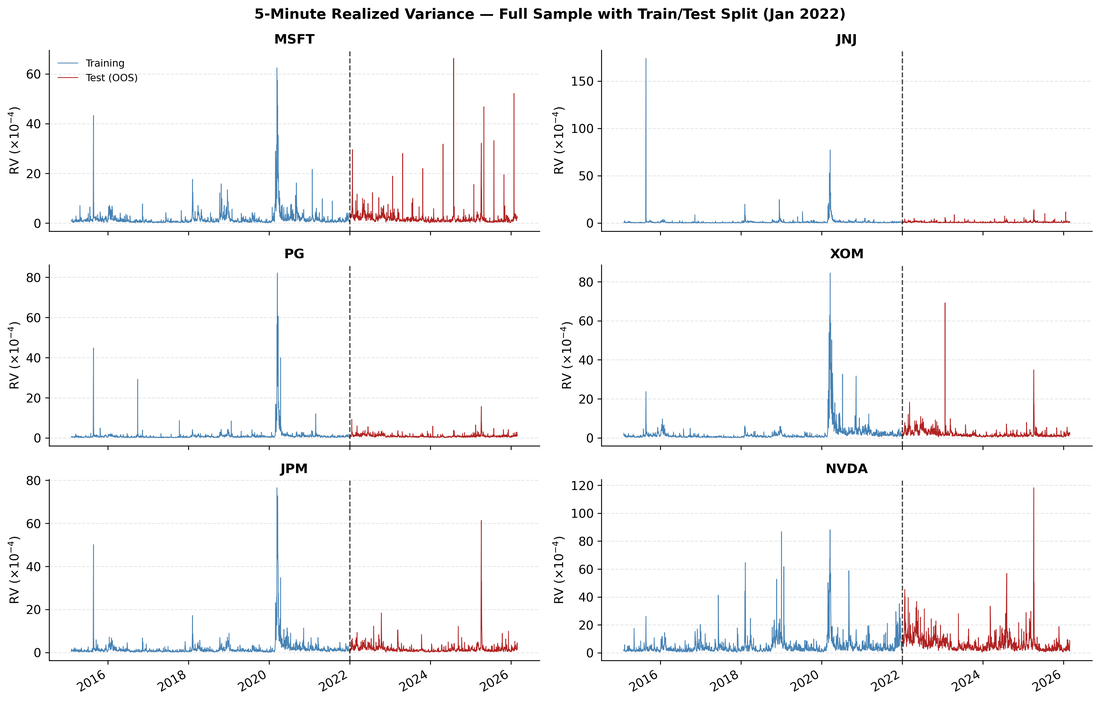

In [6]:
# ============================================================
# FIGURE 1 — Realized Variance Time Series with Train/Test Split
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=False)   # Create subplot grid
axes = axes.flatten()   # Convert subplot matrix into a flat array for easier iteration
split_ts = pd.Timestamp(split_date) # train and test split

# Plot realized variance series for each stock
for ax, stock in zip(axes, stocks):

    sdf   = df_raw[df_raw['symbol'] == stock]   # Extract stock-specific data
    train = sdf[sdf['date'] < split_date]
    test  = sdf[sdf['date'] >= split_date]

    # RV is multiplied by 10^4 purely for visual readability， since rv itself is extremely small
    ax.plot(train['date'], train['rv'] * 1e4, lw=0.7, color='steelblue',  label='Training')
    ax.plot(test['date'],  test['rv']  * 1e4, lw=0.7, color='firebrick',  label='Test (OOS)')

    # Add vertical line marking forecast orgin
    ax.axvline(split_ts, color='black', lw=1.2, ls='--', alpha=0.7) 

    # Panel title
    ax.set_title(stock, fontsize=12, fontweight='bold')

    # Y-axis label
    ax.set_ylabel(r'RV ($\times 10^{-4}$)')

    # Add horizontal gridlines
    ax.grid(axis='y', alpha=0.3, ls='--')
    
    # X-axis formatting: show year labe every 2 years 
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Display legend once
axes[0].legend(frameon=False, fontsize=9)

# Set figure title
fig.suptitle('5-Minute Realized Variance — Full Sample with Train/Test Split (Jan 2022)',
             fontsize=13, fontweight='bold')

# Improve date-label readibility
fig.autofmt_xdate(rotation=30)

# Adjust spacing between panels
plt.tight_layout()

# Export paper-quality figure
plt.savefig(f'{FIGURE_DIR}/fig1_rv_timeseries.png', dpi=300, bbox_inches='tight')

# Display figure
plt.show()

**Figure 1:** 5-minute realized variance (RV, ×10⁻⁴) for each of the six stocks over the full sample, split into the training period (blue) and out-of-sample test period (red) at the January 2022 forecast origin (dashed line). All series show the clustering and sudden spikes characteristic of realized variance, with NVDA visibly more volatile than the other five stocks — consistent with its outlier status in Table 1.

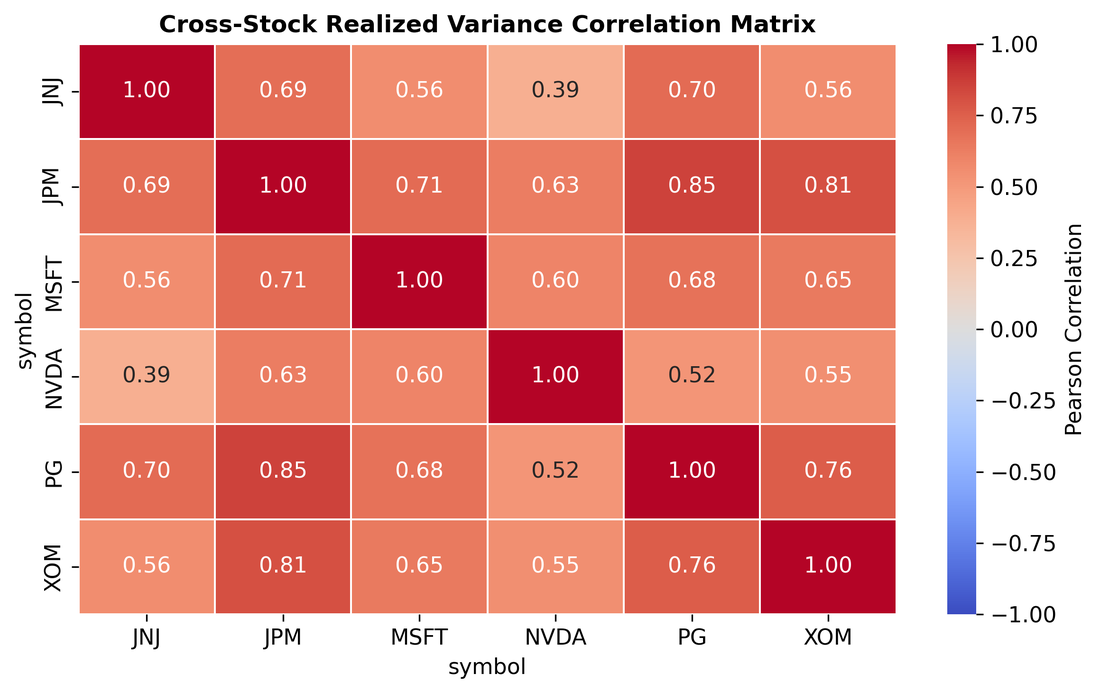

In [7]:
# ============================================================
# FIGURE 2 — Cross-Stock Realized Variance Correlation Matrix
# ============================================================

pivot = df_raw.pivot_table(index='date', columns='symbol', values='rv')
corr  = pivot.corr()

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    corr, annot=True, fmt='.2f',
    cmap='coolwarm', vmin=-1, vmax=1,
    linewidths=0.5, ax=ax,
    cbar_kws={'label': 'Pearson Correlation'}
)
ax.set_title('Cross-Stock Realized Variance Correlation Matrix', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/fig2_rv_corr_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

**Figure 2:** This figure describes a data property (cross-stock co-movement in realized variance) rather than a forecast evaluation result. Suggesting that pairwise correlations are positive across all pairs, as expected given shared exposure to broad market risk factors.

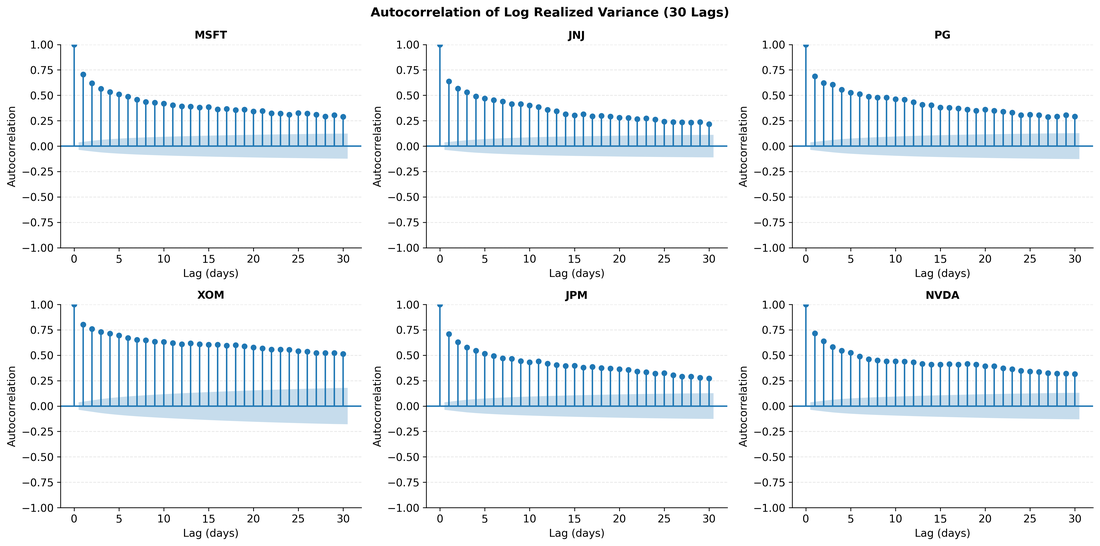

In [8]:
# ============================================================
# FIGURE 3 — Autocorrelation of Log Realized Variance
# ============================================================

from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for ax, stock in zip(axes, stocks):
    sdf = df_raw[df_raw['symbol'] == stock]
    plot_acf(sdf['log_rv'], lags=30, alpha=0.05, ax=ax, title='')
    ax.set_title(stock, fontsize=11, fontweight='bold')
    ax.set_xlabel('Lag (days)')
    ax.set_ylabel('Autocorrelation')
    ax.grid(axis='y', alpha=0.3, ls='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('Autocorrelation of Log Realized Variance (30 Lags)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/fig3_log_rv_acf.png', dpi=300, bbox_inches='tight')
plt.show()

**Figure 3:** Autocorrelations of log RV remain positive and statistically significant well beyond lag 20 for all six stocks, confirming the long-memory property of realized variance (Andersen et al., 2003). This slow decay is the econometric motivation for the HAR specification, which explicitly aggregates daily, weekly, and monthly volatility components to capture the persistence structure.

---

## 2. Forecast Evaluation

All models are evaluated over the out-of-sample period (January 2022 onward, N = 1,042 observations per stock) using a rolling estimation window re-fitted every 5 trading days. Two loss functions are reported:

- **QLIKE** *(primary)*: A proper scoring rule for variance forecasts — L(σ², h) = h/σ² − log(h/σ²) − 1. It is robust to noise in realized variance as a proxy for true conditional variance (Patton, 2011) and penalizes over- and under-prediction asymmetrically.
- **MSE**: Reported for completeness. It is not a proper scoring rule for variance and gives disproportionate weight to large errors during volatility spikes.

Where QLIKE and MSE rankings disagree, **QLIKE takes precedence**.

> **Table 2 — Caption:** Per-stock out-of-sample forecast accuracy. See the notes above for loss-function definitions and sample details. Rows sorted by QLIKE within each stock–horizon block. MSE reported in scientific notation.

In [9]:
# ============================================================
# TABLE 2 — Per-Stock Forecast Accuracy (full breakdown)
# ============================================================

# Compute forecast accuracy for each stock/horizon/model (shared with Table 3 below)
records = []
for stock in stocks:
    edf = evals[stock]
    for h in HORIZONS:
        row = scalar_metrics(edf, h)
        row['Stock']   = stock
        row['Horizon'] = h
        records.append(row)
all_metrics = pd.concat(records, ignore_index=True)

# Rank models 1 (best QLIKE) to 6 (worst) within each Stock/Horizon block
all_metrics['Rank'] = (
    all_metrics.groupby(['Stock', 'Horizon'])['QLIKE']
    .rank(method='min')
    .astype(int)
)

# Extract detailed forecast evaluation results
detail = all_metrics[['Stock', 'Horizon', 'Model', 'Rank', 'MSE', 'QLIKE']].copy()
detail = detail.sort_values(['Horizon', 'Stock', 'Rank']).reset_index(drop=True)

print('Table 2: Per-Stock Out-of-Sample Forecast Accuracy\n')

# Generate separate panels for each forecast horizon
for h in HORIZONS:
    print(f'--- h = {h} ---')
    sub = detail[detail['Horizon'] == h].drop('Horizon', axis=1)
    sub['MSE']   = sub['MSE'].map('{:.2e}'.format)
    sub['QLIKE'] = sub['QLIKE'].round(6)
    print(sub.to_string(index=False))
    print()

# Export complete stock-level results
detail.to_csv(f'{TABLE_DIR}/tab2_per_stock_accuracy.csv', index=False)


Table 2: Per-Stock Out-of-Sample Forecast Accuracy

--- h = 1 ---
Stock     Model  Rank      MSE    QLIKE
  JNJ HAR-GARCH     1 9.85e-09 0.177692
  JNJ       MLP     2 1.02e-08 0.186037
  JNJ GJR-GARCH     3 1.06e-08 0.211141
  JNJ    Hybrid     4 1.11e-08 0.214296
  JNJ   XGBoost     5 1.11e-08 0.215134
  JNJ MF2-GARCH     6 1.09e-08 0.219690
  JPM HAR-GARCH     1 5.27e-08 0.178875
  JPM       MLP     2 5.74e-08 0.183533
  JPM   XGBoost     3 6.38e-08 0.219411
  JPM    Hybrid     4 6.32e-08 0.222178
  JPM GJR-GARCH     5 6.29e-08 0.227491
  JPM MF2-GARCH     6 6.50e-08 0.232125
 MSFT   XGBoost     1 1.58e-07 0.345364
 MSFT HAR-GARCH     2 1.69e-07 0.354242
 MSFT    Hybrid     3 1.60e-07 0.354866
 MSFT       MLP     4 1.56e-07 0.371821
 MSFT GJR-GARCH     5 1.61e-07 0.395710
 MSFT MF2-GARCH     6 1.63e-07 0.404413
 NVDA HAR-GARCH     1 3.04e-07 0.153618
 NVDA       MLP     2 3.22e-07 0.158831
 NVDA   XGBoost     3 3.37e-07 0.163322
 NVDA    Hybrid     4 3.49e-07 0.169248
 NVDA MF2-GARC

**Table 2: with matched return and target windows, no model breaks down on any stock.**

Once returns are measured open-to-close --- the same trading window over which `rv5` is computed --- the extreme MF2-GARCH losses that previously appeared for NVDA disappear entirely. At h = 1, NVDA's MF2-GARCH QLIKE is 0.204 (previously 1.466), squarely in line with the other five stocks rather than an order of magnitude above them; GJR-GARCH on NVDA is 0.206. The earlier "NVDA breaks the GARCH models" result was an artefact of feeding those models close-to-close returns, whose variance for NVDA is roughly four times the intraday variance that `rv5` actually measures.

The six models are now tightly grouped within every stock: the best-to-worst QLIKE spread at h = 1 is at most 0.07 in any single stock. HAR-GARCH has the lowest QLIKE for five of the six stocks at h = 1 (all but MSFT, where XGBoost edges ahead, 0.345 vs. 0.354). The two pure GARCH models are still last or near-last on average, but no longer by a wide margin: at h = 1 their average QLIKE (GJR 0.240, MF2 0.247) sits only about 22--25 % above HAR-GARCH (0.197), whereas before the return-window correction the gap was a factor of 1.6--2.4.

> **Table 3 — Caption:** Final model ranking across six S&P 500 constituents (MSFT, JNJ, PG, XOM, JPM, NVDA), by forecast horizon. Models are ranked 1 (best) to 6 (worst) by QLIKE within each stock, then the rank is averaged across the six stocks — more robust to a single stock's outlier loss than averaging raw QLIKE directly across stocks (see discussion below and Table 2). Out-of-sample period: January 2022 – February 2026 (N = 1,042 observations per stock).

In [ ]:
# ============================================================
# TABLE 3 — Final Model Ranking (Rank-then-Average)
# ============================================================
rank_rows = []

# Compute model ranks for each stock and horizon
for stock in stocks:
    edf = evals[stock]

    for h in HORIZONS:
        scores = scalar_metrics(edf, h).set_index('Model')['QLIKE']

        # Convert losses into rankings
        for model, rank in scores.rank().items():
            rank_rows.append({'Stock': stock, 'h': f'h={h}', 'Model': model, 'Rank': rank})

# Convert rank records into DataFrame
rank_df = pd.DataFrame(rank_rows)

# Average rankings across stocks (shared with Figure 4 below)
pivot = (
    rank_df.groupby(['Model', 'h'])['Rank']
    .mean()
    .unstack('h')
    .loc[lambda d: d.mean(axis=1).sort_values().index]  # best -> worst rows
)

final_rank = pivot[['h=1', 'h=5', 'h=22']].round(2)
final_rank.index.name = 'Model'
final_rank = final_rank.sort_values('h=1')

print('Table 3: Final Model Ranking -- Average Rank Across 6 Stocks (1 = best QLIKE, 6 = worst)\n')
print(final_rank.to_string())

final_rank.to_csv(f'{TABLE_DIR}/tab3_final_ranking.csv')


Table 3: Final Model Ranking -- Average Rank Across 6 Stocks (1 = best QLIKE, 6 = worst)

h           h=1   h=5  h=22
Model                      
HAR-GARCH  1.17  1.67  2.33
MLP        2.33  2.00  1.67
XGBoost    3.50  3.83  4.83
Hybrid     4.00  4.00  3.00
GJR-GARCH  4.50  4.33  4.33
MF2-GARCH  5.50  5.17  4.83


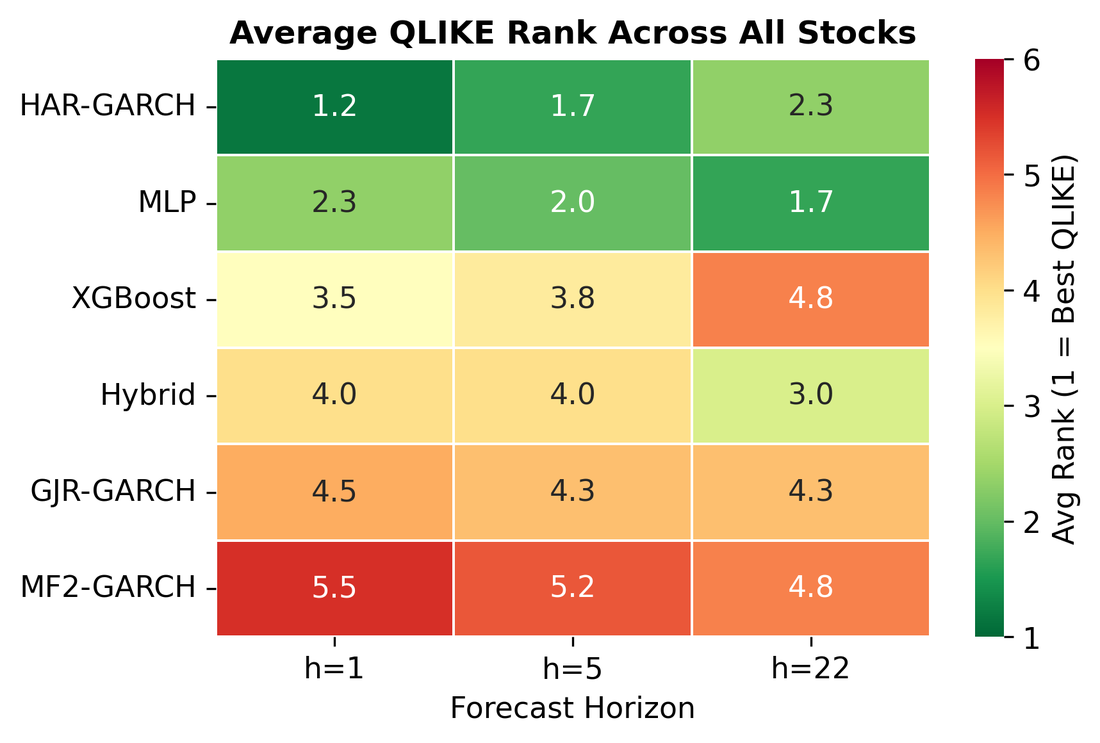

In [ ]:
# ============================================================
# FIGURE 4 — QLIKE Rank Heatmap (average rank across stocks)
# ============================================================

fig, ax = plt.subplots(figsize=(6, 4))

sns.heatmap(
    final_rank, annot=True, fmt='.1f',
    cmap='RdYlGn_r', vmin=1, vmax=len(available),
    linewidths=0.5, ax=ax,
    cbar_kws={'label': 'Avg Rank (1 = Best QLIKE)'}
)

ax.set_title('Average QLIKE Rank Across All Stocks', fontsize=12, fontweight='bold')
ax.set_xlabel('Forecast Horizon')
ax.set_ylabel('')

plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/fig4_rank_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

**Table 3** and **Figure 4** summarize average QLIKE ranks across all six stocks (Table 3: the average ranks, listed by horizon; Figure 4: the same data as a heatmap, green = rank 1 best, red = rank 6 worst).

Three patterns emerge:
1. **HAR-GARCH is the model to beat at the short and medium horizons.** It has the best average rank at h = 1 (1.17) and h = 5 (1.67), and is a close second at h = 22 (2.33). A parsimonious linear model in daily/weekly/monthly log-RV, plus the LHAR leverage term, is therefore highly competitive --- the machine-learning models do **not** uniformly dominate it.
2. **The neural network takes the lead only at the longest horizon.** MLP ranks 2nd at h = 1 (2.33) and 2nd at h = 5 (2.00), but 1st at h = 22 (1.67), where low-frequency volatility structure matters most. The Hybrid (MF2-GARCH state features + XGBoost) is 3rd at h = 22 (3.00) and clearly beats plain XGBoost (4.83) there, though XGBoost is ahead of it at h = 1 (3.50 vs. 4.00) and h = 5 (3.83 vs. 4.00) --- so the econometric state features help the tree model only at the long horizon.
3. **The pure GARCH models are still weakest, but the gap has narrowed sharply.** GJR-GARCH (4.50 / 4.33 / 4.33) and MF2-GARCH (5.50 / 5.17 / 4.83) sit at the bottom, yet at h = 22 GJR-GARCH actually **outranks XGBoost** (4.33 vs. 4.83) and beats it on average QLIKE (0.114 vs. 0.121). Once the return window is matched to the target, a pure conditional-variance model is no longer uniformly inferior to gradient boosting.

**Rank-then-average versus raw-QLIKE averaging.** Ranking within each stock before averaging bounds each stock's contribution to 1--6 regardless of how extreme its underlying loss is, and is reported as the headline comparison. With the corrected return window no stock now produces an outlier loss, so the two summaries agree closely --- but the rank-based statistic remains the more robust choice.

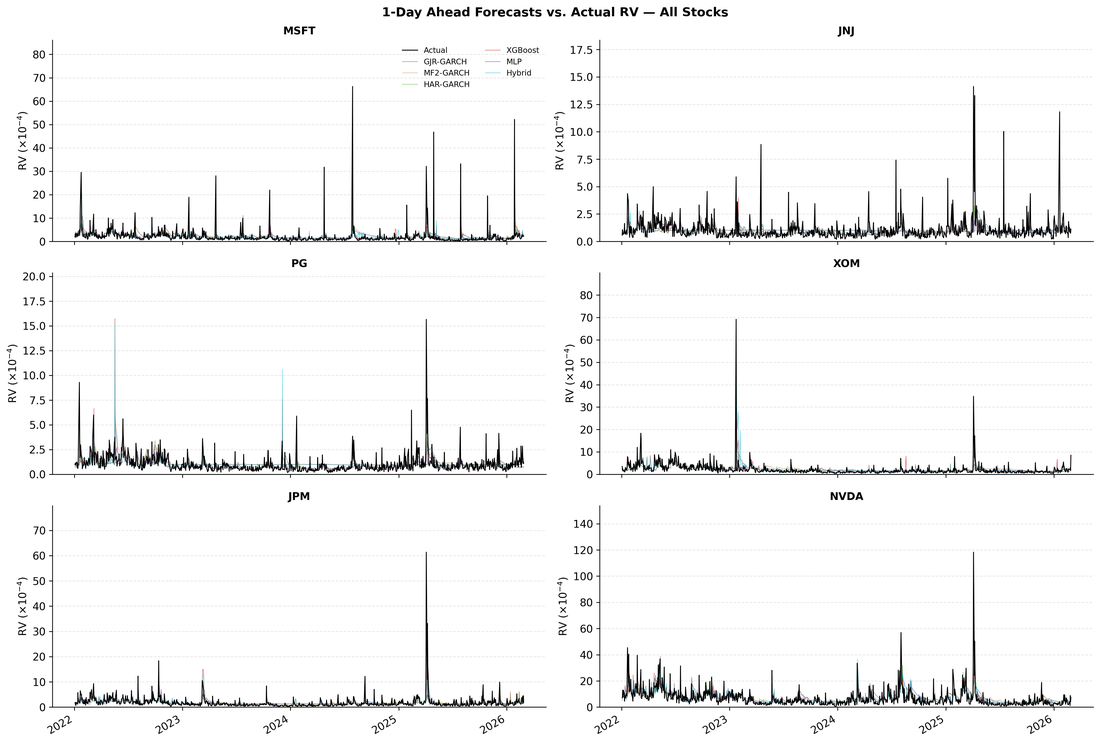

In [12]:
# ============================================================
# FIGURE 5 — Actual vs. Forecast, All Stocks (h = 1)
# ============================================================
plot_forecast_grid(1, 'fig5_forecast_all_h1', '1-Day Ahead Forecasts vs. Actual RV — All Stocks')

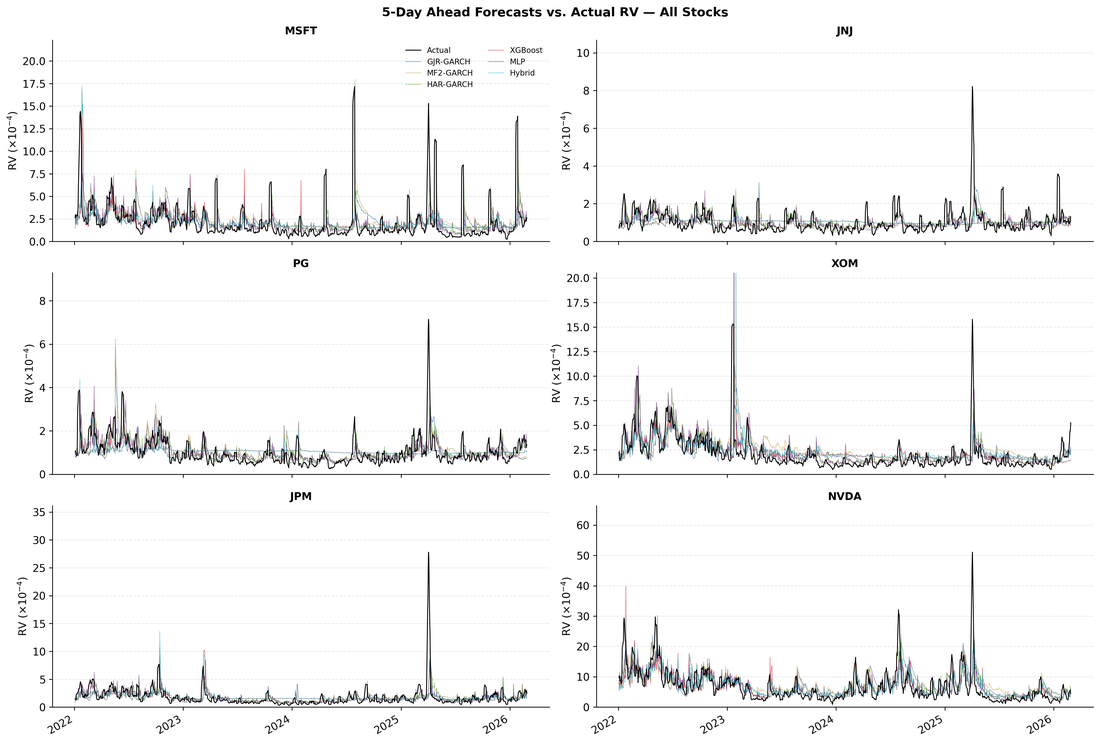

In [13]:
# ============================================================
# FIGURE 6 — Actual vs. Forecast, All Stocks (h = 5)
# ============================================================
plot_forecast_grid(5, 'fig6_forecast_all_h5', '5-Day Ahead Forecasts vs. Actual RV — All Stocks')

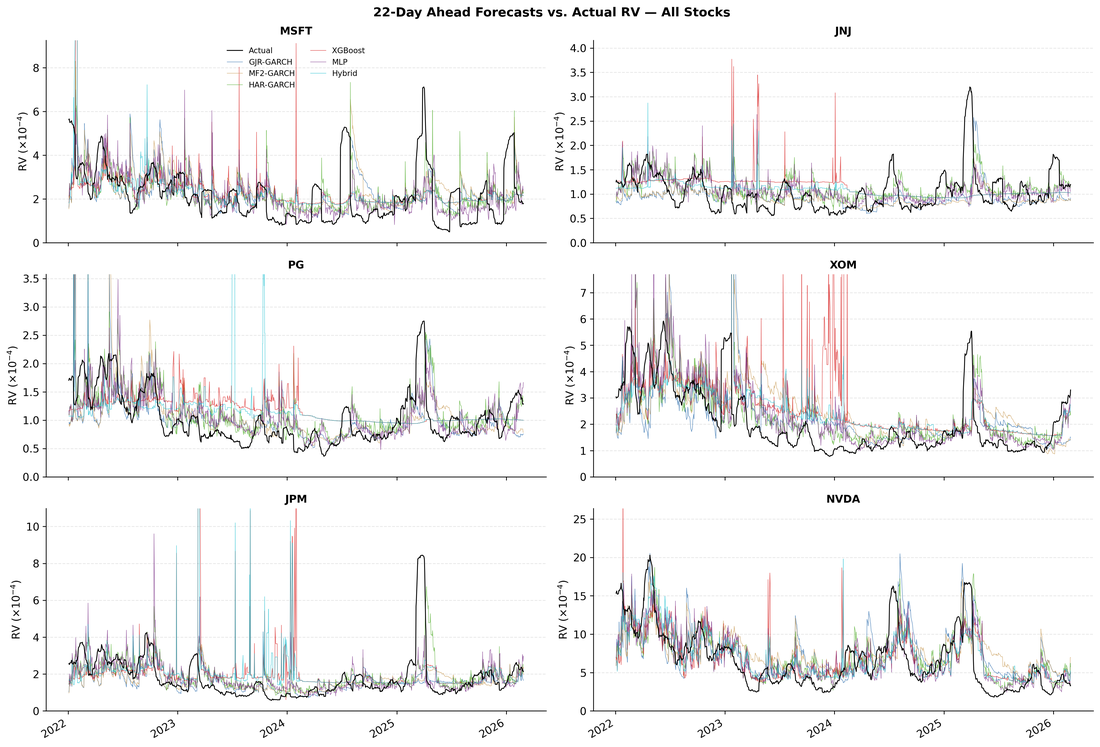

In [14]:
# ============================================================
# FIGURE 7 — Actual vs. Forecast, All Stocks (h = 22)
# ============================================================
plot_forecast_grid(22, 'fig7_forecast_all_h22', '22-Day Ahead Forecasts vs. Actual RV — All Stocks')

**Figures 5—7 — Actual vs. Forecast, All Stocks (h = 1, 5, 22):** With returns measured open-to-close, all six models now track the realized-variance path at a comparable level for every stock, including NVDA --- the earlier decoupling of MF2-GARCH from NVDA's actual RV is gone, and the GARCH forecasts sit close to the target rather than displaying the large positive bias of the earlier close-to-close specification (mean forecast / mean actual at h = 1 is 1.04 for GJR-GARCH and 1.06 for MF2-GARCH, a mild 4--6 % over-prediction). The remaining visible pattern is common to all models: they increasingly lag sudden volatility spikes as the horizon lengthens, reacting a few days after the jump rather than anticipating it, and by h = 22 the 5-day rolling re-estimation produces smoother, slower-moving forecasts that trail fast regime shifts. Among the models the visible differences are small, consistent with the per-stock MCS retaining several models in most stocks. One structural difference is visible at the longer horizons: XGBoost and the Hybrid trace a **staircase** rather than a smooth path. Both are tree ensembles, so their forecast is piecewise constant --- with `max_depth = 3` the daily movement in the features rarely crosses a split threshold, and the prediction stays in the same leaf for the entire 5-day re-estimation window before stepping to a new value (at h = 22 the two models take only 224--929 distinct values across 1,042 forecast days, versus 1,042 for the four continuous models). This inability to track a smoothly evolving target is one reason XGBoost falls to the bottom of the RV-based group at h = 22.

For readability each panel's y-axis is capped at 1.3x that stock's maximum realized RV.

### Statistical Significance of Forecast Accuracy Differences

Point-estimate rankings cannot distinguish genuine predictive ability from sampling noise. The Model Confidence Set addresses this:

- **Model Confidence Set (MCS, Table 4):** For each stock, identifies the smallest set of models for which the equal-predictive-ability null cannot be rejected at α = 10 %. It is multiple-comparison consistent and eliminates the worst models sequentially (Hansen et al., 2011).

Because the MCS compares all six models jointly and is robust to multiple comparisons, no pairwise Diebold-Mariano tests are reported: averaging DM p-values across stocks is a descriptive summary rather than a valid combined test.

> **Table 4 — Caption:** Model Confidence Set (Hansen, Lunde & Nason, 2011) estimated separately for each stock. Loss function: QLIKE; α = 10 %; circular block bootstrap with B = 1,000 replications; N = 1,042 observations per stock. The block length is set per horizon as l = max(10, 2h) — that is, l = 10 at h = 1 and h = 5, and l = 44 at h = 22 — because the h-step target averages RV over [t+1, t+h], leaving consecutive losses MA(h−1) dependent; a block shorter than that overlap would sever dependence the data actually has and make the test over-reject. Each cell lists the models retained in the MCS for that stock and horizon, ordered from lowest to highest average QLIKE. The MCS is run per stock — rather than pooling the loss series across stocks — so that a single high-loss stock (e.g. NVDA) cannot dominate the comparison, consistent with the rank-based summary in Table 3.

In [ ]:
# ============================================================
# TABLE 4 — Model Confidence Set by Stock
# ============================================================
# The MCS is run within each stock (not pooled across stocks) so that a single
# high-loss stock cannot sway the result — consistent with the rank-then-average
# summary in Table 3.
#
# The circular block length is set per horizon via block_length_for_horizon().
# The h = 5 and h = 22 targets average RV over [t+1, t+h], so consecutive losses
# share h-1 of their h daily terms and the loss series is MA(h-1) dependent. A
# block shorter than that overlap severs dependence the data actually has, which
# narrows the bootstrap null of T_max and makes the procedure over-reject —
# returning confidence sets that are too small. l = max(10, 2h) leaves h = 1 and
# h = 5 at l = 10 and raises the monthly horizon to l = 44.

mcs_stock_rows = []

for stock in stocks:
    row = {'Stock': stock}

    for h in HORIZONS:
        losses = loss_series_df(evals[stock], h, loss='qlike')

        mcs = ModelConfidenceSet(
            alpha=0.10,                                # α = 10%
            B=1000,                                    # 1000 bootstrap replications
            block_length=block_length_for_horizon(h),  # l = max(10, 2h)
            random_state=42
        )
        survivors = mcs.fit(losses)

        # Order survivors best -> worst by mean QLIKE
        ordered = losses[survivors].mean().sort_values().index.tolist()
        row[f'h={h}'] = ', '.join(ordered)

    mcs_stock_rows.append(row)

t4b = pd.DataFrame(mcs_stock_rows).set_index('Stock')

blocks = ', '.join(f'h={h}: l={block_length_for_horizon(h)}' for h in HORIZONS)
print('Table 4: MCS Survivors by Stock (α=10%, QLIKE)')
print(f'Circular block bootstrap, B=1000  |  block lengths — {blocks}')
print(t4b.to_string())
t4b.to_csv(f'{TABLE_DIR}/tab4_mcs_per_stock.csv')


Table 4: MCS Survivors by Stock (α=10%, QLIKE)
Circular block bootstrap, B=1000  |  block lengths — h=1: l=10, h=5: l=10, h=22: l=44
                                                         h=1                                                    h=5                                                   h=22
Stock                                                                                                                                                                     
MSFT   XGBoost, HAR-GARCH, Hybrid, MLP, GJR-GARCH, MF2-GARCH                        XGBoost, Hybrid, MLP, HAR-GARCH                        Hybrid, XGBoost, MLP, HAR-GARCH
JNJ    HAR-GARCH, MLP, GJR-GARCH, Hybrid, XGBoost, MF2-GARCH  HAR-GARCH, MLP, Hybrid, GJR-GARCH, XGBoost, MF2-GARCH  HAR-GARCH, MLP, Hybrid, MF2-GARCH, GJR-GARCH, XGBoost
PG                                            HAR-GARCH, MLP                                         MLP, HAR-GARCH                   MLP, HAR-GARCH, GJR-GARCH, MF2-GARCH
XOM         

**MCS results — Table 4 (per stock):**

- **HAR-GARCH is the most robust model across the cross-section.** It is retained in the confidence set for **all six stocks at all three horizons**, and is the *sole* survivor for NVDA at h = 1.
- **MLP is HAR-GARCH's main rival, and strengthens with horizon.** It survives in five of six stocks at h = 1 (all but NVDA), and in all six at both h = 5 and h = 22.
- **The pure GARCH models now survive far more often than before.** With the corrected return window, GJR-GARCH and MF2-GARCH are both retained for MSFT, JNJ and JPM at h = 1, and for JNJ, PG and JPM at h = 22 --- whereas previously they were eliminated almost everywhere. The test can no longer separate them from the RV-based models in the calmer series.
- **The Hybrid is broadly competitive at the long horizon**, entering the MCS for five of six stocks at h = 22 (all but PG), including the volatile technology names MSFT and NVDA.

Because the models are now much closer together, the MCS is less discriminating: for MSFT, JNJ and JPM at h = 1 the test cannot drop any model at all (the full six-model set is retained). This is itself informative --- much of the apparent superiority of the RV-based models in the earlier specification came from the GARCH models' mismatched forecast scale, not from genuinely worse dynamics.

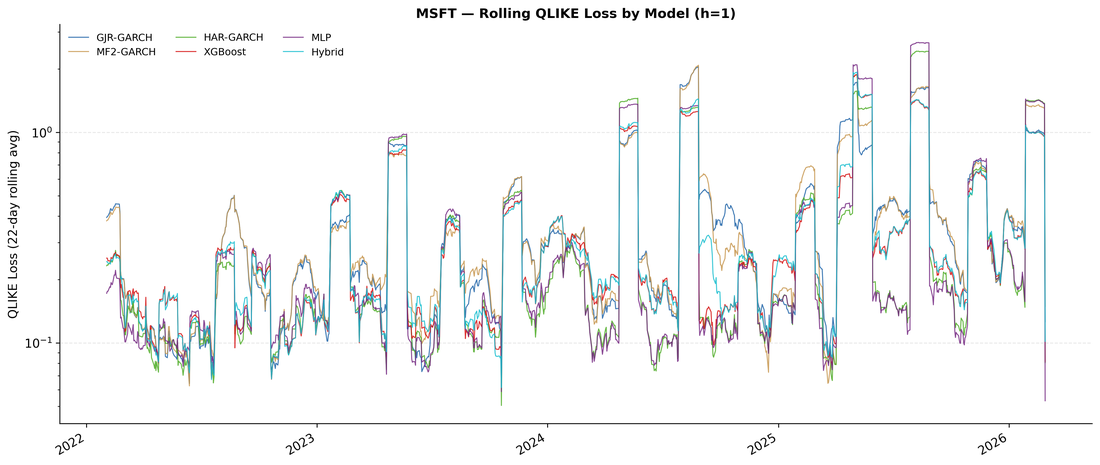

In [16]:
# ============================================================
# FIGURE 8 — Daily QLIKE Loss Time Series (MSFT, h = 1)
# ============================================================

stock = 'MSFT'
h     = 1
edf   = evals[stock]

# Compute daily QLIKE loss series for all models
loss_df = loss_series_df(edf, h, loss='qlike')

# Smooth loss series using a 22-trading-day rolling average
loss_smooth = loss_df.rolling(22, min_periods=22).mean()
loss_smooth['date'] = edf['date'].values

fig, ax = plt.subplots(figsize=(14, 6))

# Plot smoothed loss trajectory for each model
for i, col in enumerate(loss_df.columns):
    
    ax.plot(loss_smooth['date'], loss_smooth[col],
            lw=0.9, alpha=0.85, color=COLORS[i], label=col)

ax.set_ylabel('QLIKE Loss (22-day rolling avg)')
ax.set_title(f'{stock} — Rolling QLIKE Loss by Model (h=1)',
             fontsize=12, fontweight='bold')
ax.legend(frameon=False, ncol=3, fontsize=9)
ax.grid(axis='y', alpha=0.3, ls='--')
ax.set_yscale('log')        # Logarithmic scaling improves visibility
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.autofmt_xdate(rotation=30)

plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/fig8_qlike_loss_series.png', dpi=300, bbox_inches='tight')
plt.show()

**Figure 8 — Rolling QLIKE Loss by Model (MSFT, h = 1):** 22-day rolling average of daily QLIKE loss for each model. Loss spikes recur periodically (roughly semi-annually) and hit all six models at the same time, indicating shared volatility-regime shocks (e.g. earnings, macro events) rather than model-specific failures. Between spikes, HAR-GARCH and MLP sit modestly below the other four models, consistent with the average QLIKE ranking in Table 3; with the corrected return window the GARCH models are no longer dramatically separated from the RV-based forecasters.


---

## 3. Parameter Estimates and Supplementary Figures

The following tables and figures provide supporting detail for the main results. They surve as supplementarys in my thesis.

**Rolling window setup:** All parametric models (GJR-GARCH, HAR-GARCH, MF2-GARCH) are re-estimated every 5 trading days using a fixed-length moving window. Table 5 reports time-series averages of the estimated parameter vectors across all rolling windows.

> **Table 5 — Caption:** Time-series averages of estimated parameters across all rolling windows. Rolling window re-fitted every 5 trading days; out-of-sample period begins January 2022. GJR-GARCH: QMLE with Student-’t‘ innovations (ν: estimated degrees of freedom). HAR-GARCH: OLS on log RV with separate regressions for h = 1, 5, 22 days. MF2-GARCH: MLE; long-run component smoothed over m = 63 trading days (one calendar quarter). Stocks: MSFT, JNJ, PG, XOM, JPM, NVDA.

In [17]:
# ============================================================
# TABLE 5 — Average Parameter Estimates Across Rolling Windows
# ============================================================

for key, tag, label in [
    ('gjr', 'GJR', 'GJR-GARCH'),
    ('har', 'HAR', 'HAR-GARCH'),
    ('mf2', 'MF2', 'MF2-GARCH'),
]:
    stock_means = []
    for stock in stocks:
        path = f'{TABLE_DIR}/{stock}_{tag}_params.csv'
        if os.path.exists(path):
            p  = pd.read_csv(path, index_col=0)
            mu = p.mean()   # Average across rolling refits
            mu.name = stock
            stock_means.append(mu)

    if stock_means:
        tbl = pd.DataFrame(stock_means).round(4)
        tbl.index.name = 'Stock'
        print(f'\nTable 5 ({label}): Average Parameter Estimates Across Rolling Windows\n')
        print(tbl.to_string())
        tbl.to_csv(f'{TABLE_DIR}/tab5_{tag}_params.csv')


Table 5 (GJR-GARCH): Average Parameter Estimates Across Rolling Windows

        omega  alpha[1]  gamma[1]  beta[1]       nu
Stock                                              
MSFT   0.0541    0.0335    0.0393   0.9244   6.1460
JNJ    0.0568    0.0455    0.0157   0.8880   5.5080
PG     0.0509    0.0509    0.0502   0.8783   6.4228
XOM    0.0496    0.0330    0.0332   0.9295  10.7526
JPM    0.1555    0.0338    0.0987   0.8224   7.1628
NVDA   0.1590    0.0244    0.0795   0.9157   8.1274

Table 5 (HAR-GARCH): Average Parameter Estimates Across Rolling Windows

       h1_const  h1_log_rv_d  h1_log_rv_w  h1_log_rv_m  h1_ret_neg  h5_const  h5_log_rv_d  h5_log_rv_w  h5_log_rv_m  h5_ret_neg  h22_const  h22_log_rv_d  h22_log_rv_w  h22_log_rv_m  h22_ret_neg
Stock                                                                                                                                                                                            
MSFT    -1.8935       0.4016       0.2476       

**Key observation — Table 5:**

**GJR-GARCH:** With open-to-close returns the cross-section is remarkably homogeneous. The intercept $\omega$ now ranges only from 0.050 (XOM) to 0.159 (NVDA) --- the earlier NVDA outlier ($\omega \approx 4.58$, ~34x the next stock) has disappeared entirely. Total persistence ($\alpha + \gamma/2 + \beta$) lies between 0.906 (JPM) and 0.980 (XOM, NVDA); NVDA is now among the *most* persistent stocks rather than the least. The leverage coefficient $\gamma$ is positive for all six stocks, confirming the asymmetric response to negative returns.

**HAR-GARCH:** The daily component leads at h = 1 ($\hat\beta_d \approx 0.29$--$0.40$), and weight migrates to the monthly component as the horizon lengthens ($\hat\beta_m \approx 0.19$--$0.37$ at h = 22), while the intercept becomes strongly negative. The log-RV coefficients sum to well below one at the longer horizons, reflecting mean reversion. The LHAR leverage coefficient $\hat\beta_{r^-}$ on $\min(r_t, 0)$ is **negative for every stock at every horizon** (h = 1: $-0.010$ to $-0.094$) and shrinks steadily with horizon --- exactly the asymmetry GJR- and MF2-GARCH capture through $\gamma$, and a far cleaner result than the signed-return term it replaced (which was statistically insignificant for three of the six stocks).

**MF2-GARCH:** Long-run persistence $\hat\phi$ ranges from 0.836 (JPM) to 0.988 (XOM), and $\hat\lambda_2$ from 0.746 (JNJ) to 0.909 (XOM). NVDA's parameters are now unremarkable ($\hat\beta = 0.841$, $\hat\lambda_2 = 0.853$), where previously they signalled a collapsed short-run component and a near-unit-root long-run component. It is now **XOM** that comes closest to the non-stationary boundary ($\hat\phi = 0.988$, $\hat\lambda_1 \approx 0.002$).

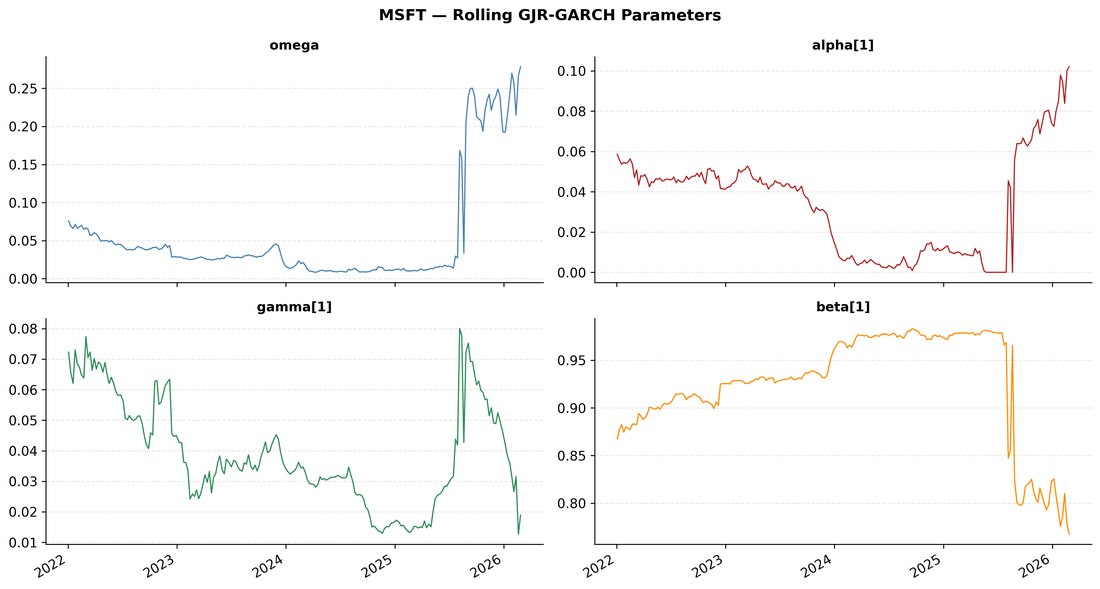

In [18]:
# ============================================================
# FIGURE 9 — Rolling GJR-GARCH Parameters Over Time (MSFT)
# ============================================================

stock = 'MSFT'
path  = f'{TABLE_DIR}/{stock}_GJR_params.csv'   # Load rolling parameter estimates

if os.path.exists(path):
    params = pd.read_csv(path, index_col=0, parse_dates=True)
    params.index = pd.to_datetime(params.index)


    # Select core GJR-GARCH parameters
    param_cols = [c for c in params.columns][:4]   # omega, alpha, gamma, beta

    fig, axes  = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
    axes = axes.flatten()
    clrs = ['steelblue', 'firebrick', 'seagreen', 'darkorange']

    # Plot rolling parameter paths
    for ax, col, clr in zip(axes, param_cols, clrs):

        ax.plot(params.index, params[col], lw=1.0, color=clr)

        ax.set_title(col, fontsize=11, fontweight='bold')
        ax.grid(axis='y', alpha=0.3, ls='--')
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    fig.suptitle(f'{stock} — Rolling GJR-GARCH Parameters',
                 fontsize=13, fontweight='bold')
    fig.autofmt_xdate(rotation=30)
    
    plt.tight_layout()
    plt.savefig(f'{FIGURE_DIR}/fig9_gjr_rolling_params.png', dpi=300, bbox_inches='tight')
    plt.show()

# In case of missing parameter file
else:
    print(f'{path} not found — run 3_forecasts.ipynb first.')

**Figure 9 — Rolling GJR-GARCH Parameters (MSFT):** MSFT's rolling estimates show the usual trade-off between long-run persistence ($\beta$) and the reactive/asymmetric terms ($\omega$, $\alpha$, $\gamma$): $\beta$ starts near 0.87 in early 2022, peaks around 0.98, and eases back to roughly 0.77 in the final windows. $\alpha$ sits at essentially zero in about 17 % of the 209 rolling windows --- an optimizer corner solution that arises once $\beta$ absorbs most of the persistence. The parameter paths are noticeably better behaved than under the previous close-to-close specification, where the overnight component inflated the reactive terms.

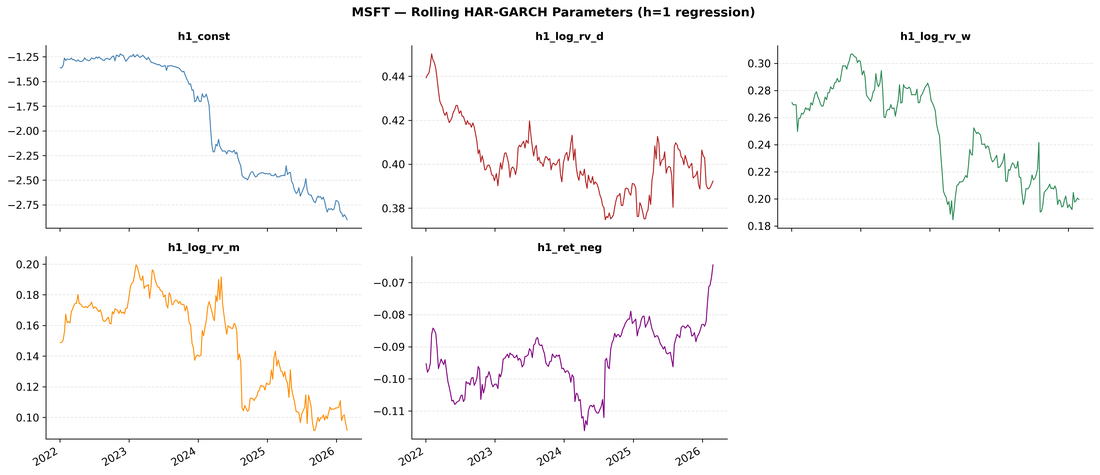

In [19]:
# ============================================================
# FIGURE 10 — Rolling HAR-GARCH Parameters Over Time (MSFT)
# ============================================================

stock = 'MSFT'
path  = f'{TABLE_DIR}/{stock}_HAR_params.csv'   # Load rolling parameter estimates

if os.path.exists(path):
    params = pd.read_csv(path, index_col=0, parse_dates=True)
    params.index = pd.to_datetime(params.index)

    # h=1 regression coefficients: intercept + daily/weekly/monthly log-RV components + ret leverage term
    param_cols = ['h1_const', 'h1_log_rv_d', 'h1_log_rv_w', 'h1_log_rv_m', 'h1_ret_neg']

    fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
    axes = axes.flatten()
    axes[-1].set_visible(False)  # 5 params in a 2x3 grid, last slot unused
    clrs = ['steelblue', 'firebrick', 'seagreen', 'darkorange', 'purple']

    # Plot rolling parameter paths
    for ax, col, clr in zip(axes, param_cols, clrs):

        ax.plot(params.index, params[col], lw=1.0, color=clr)

        ax.set_title(col, fontsize=11, fontweight='bold')
        ax.grid(axis='y', alpha=0.3, ls='--')
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    fig.suptitle(f'{stock} — Rolling HAR-GARCH Parameters (h=1 regression)',
                 fontsize=13, fontweight='bold')
    fig.autofmt_xdate(rotation=30)

    plt.tight_layout()
    plt.savefig(f'{FIGURE_DIR}/fig10_har_rolling_params.png', dpi=300, bbox_inches='tight')
    plt.show()

# In case of missing parameter file
else:
    print(f'{path} not found — run 3_forecasts.ipynb first.')


**Figure 10 — Rolling HAR-GARCH Parameters (MSFT, h=1 regression):** The four coefficients of the h = 1 regression are shown alongside the LHAR leverage term $\min(r_t, 0)$. The daily/weekly/monthly ordering (log_rv_d > log_rv_w > log_rv_m) and the intercept's late-sample decline (from about $-1.36$ in 2022 to $-2.90$ by 2026) are stable across all 209 rolling windows. The leverage coefficient h1_ret_neg is **negative in every single window** (range $-0.116$ to $-0.064$, mean $-0.094$), never crossing zero: a negative return raises the h = 1 RV forecast, exactly as GJR-GARCH's and MF2-GARCH's $\gamma$ terms predict. Its magnitude shrinks steadily with horizon (MSFT mean $-0.094$ at h = 1, $-0.046$ at h = 5, $-0.019$ at h = 22), consistent with a leverage shock that fades over longer horizons.

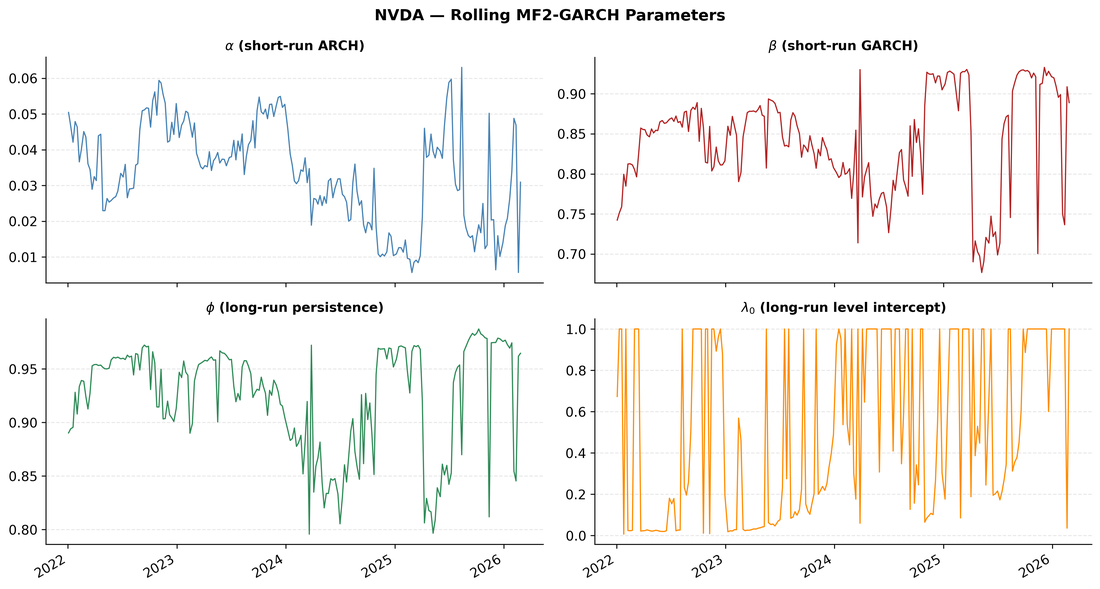

In [20]:
# ============================================================
# FIGURE 11 — Rolling MF2-GARCH Parameters Over Time (NVDA)
# ============================================================

# Rolling MF2-GARCH parameter paths for NVDA. Under the earlier close-to-close return
# specification these paths signalled a numerical breakdown (collapsed short-run beta,
# near-unit-root long-run lambda2, QLIKE > 1.4). With returns measured open-to-close
# — matched to the rv5 window — the paths are well behaved: this figure documents that
# the instability is resolved. See the caption below for the before/after comparison.

stock = "NVDA"
path  = f"{TABLE_DIR}/{stock}_MF2_params.csv"

if os.path.exists(path):
    params = pd.read_csv(path, index_col=0, parse_dates=True)
    params.index = pd.to_datetime(params.index)

    # Four economically interpretable parameters
    plot_params = {
        "alpha":   r"$\alpha$ (short-run ARCH)",
        "beta":    r"$\beta$ (short-run GARCH)",
        "phi":     r"$\phi$ (long-run persistence)",
        "lambda0": r"$\lambda_0$ (long-run level intercept)",
    }

    fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
    axes = axes.flatten()
    clrs = ["steelblue", "firebrick", "seagreen", "darkorange"]

    for ax, (col, label), clr in zip(axes, plot_params.items(), clrs):
        if col not in params.columns:
            ax.set_visible(False)
            continue
        ax.plot(params.index, params[col], lw=1.0, color=clr)
        ax.set_title(label, fontsize=11, fontweight="bold")
        ax.grid(axis="y", alpha=0.3, ls="--")
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    fig.suptitle(
        f"{stock} — Rolling MF2-GARCH Parameters",
        fontsize=13, fontweight="bold"
    )
    fig.autofmt_xdate(rotation=30)
    
    plt.tight_layout()
    plt.savefig(f"{FIGURE_DIR}/fig11_mf2_nvda_rolling_params.png", dpi=300, bbox_inches="tight")
    plt.show()

else:
    print(f"{path} not found — run 3_forecasts.ipynb first.")

**Figure 11 — Rolling MF2-GARCH Parameters for NVDA:**

This figure originally documented a numerical failure. It no longer does, and that is the point worth making.

Under the previous close-to-close return specification, NVDA's MF2-GARCH estimates showed a collapsed short-run component ($\beta \approx 0.58$) and a near-unit-root long-run component ($\lambda_2 \approx 0.996$), producing QLIKE losses an order of magnitude above every other model-stock pair. Once returns are measured open-to-close --- matching the window over which `rv5` is computed --- those pathologies vanish: across the rolling windows $\beta$ averages 0.841 and $\lambda_2$ averages 0.853, both squarely within the range of the other five stocks, and NVDA's QLIKE falls from 1.466 to 0.204 at h = 1.

The lesson is about measurement, not about the model. NVDA's volatility is unusually concentrated in overnight moves (earnings and AI-related news), so its close-to-close return variance is roughly four times the intraday variance that `rv5` records. Forcing MF2-GARCH to explain that extra overnight variation with a target that never contains it drove the long-run component toward a unit root. With the two windows aligned, the two-component decomposition is well identified for NVDA. A handful of individual windows still reach $\lambda_2 \approx 0.998$, so the long-run component remains the more delicate of the two to estimate, but there is no systematic breakdown.

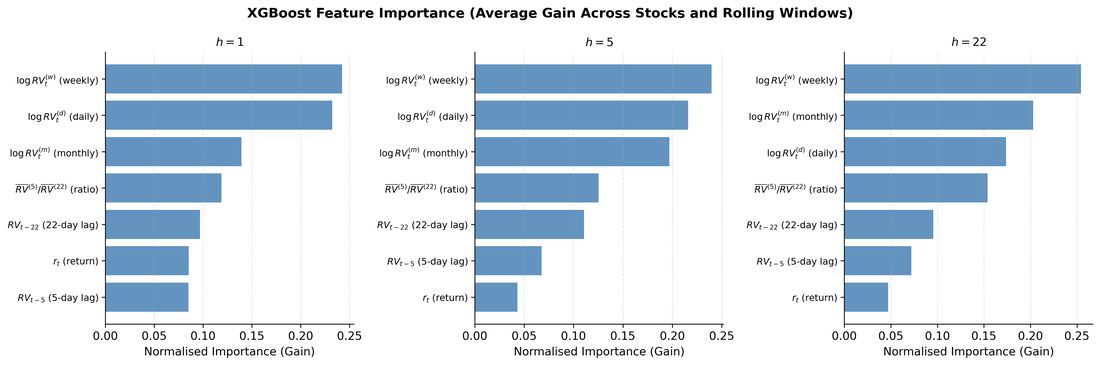

In [ ]:
# ============================================================
# FIGURE 12 — XGBoost Feature Importance (rolling refits)
# ============================================================
# Importance is averaged over ALL rolling re-estimation windows that generate
# the OOS forecasts, so it characterises the models actually scored in 
# Tables 2-4 rather than a single fit. This is slow: 6 stocks x ~209 refits.

from src.models.xgboost_model import XGBoostModel

FEAT_LABELS = {
    'log_rv_d':  r'$\log RV_t^{(d)}$ (daily)',
    'log_rv_w':  r'$\log RV_t^{(w)}$ (weekly)',
    'log_rv_m':  r'$\log RV_t^{(m)}$ (monthly)',
    'rv_lag_5':  r'$RV_{t-5}$ (5-day lag)',
    'rv_lag_22': r'$RV_{t-22}$ (22-day lag)',
    'rv_ratio':  r'$\overline{RV}^{(5)}/\overline{RV}^{(22)}$ (ratio)',
    'ret':       r'$r_t$ (return)',
}

# Walk the same rolling windows used for forecasting; collect gain at each refit
imp_frames = []

for stock in stocks:
    sdf   = df_raw[df_raw['symbol'] == stock].copy()
    train = sdf[sdf['date'] <  split_date]
    test  = sdf[sdf['date'] >= split_date]
    rolling_df = train.copy()

    for t in range(len(test)):
        if t % refit_frequency == 0:
            window = rolling_df.iloc[-rolling_window:]
            m = XGBoostModel()
            m.fit(window[xgb_features], window)
            imp = m.feature_importance()
            imp['stock'] = stock
            imp_frames.append(imp)
        rolling_df = pd.concat([rolling_df, test.iloc[t:t+1]]).iloc[-rolling_window:]

imp_all = pd.concat(imp_frames, ignore_index=True)

# Mean within stock across refits, then across stocks (equal refit counts make
# this a simple pooled mean), normalised so each horizon sums to 1.
per_stock = imp_all.groupby(['stock', 'horizon', 'feature'])['importance'].mean().reset_index()
avg_imp   = per_stock.groupby(['horizon', 'feature'])['importance'].mean().reset_index()
avg_imp['importance'] = avg_imp.groupby('horizon')['importance'].transform(lambda x: x / x.sum())

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=False)

for ax, h in zip(axes, HORIZONS):
    sub = avg_imp[avg_imp['horizon'] == h].sort_values('importance')
    labels = [FEAT_LABELS.get(f, f) for f in sub['feature']]
    ax.barh(labels, sub['importance'], color='steelblue', alpha=0.85)
    ax.set_title(f'$h = {h}$', fontsize=11, fontweight='bold')
    ax.set_xlabel('Normalised Importance (Gain)')
    ax.grid(axis='x', alpha=0.3, ls='--')
    ax.tick_params(axis='y', labelsize=9)

fig.suptitle('XGBoost Feature Importance (Average Gain Across Stocks and Rolling Windows)',
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/fig12_xgb_importance.png', dpi=300, bbox_inches='tight')
plt.show()

avg_imp.pivot(index='feature', columns='horizon', values='importance').round(4).to_csv(
    f'{TABLE_DIR}/fig12_xgb_importance.csv'
)

**Figure 12 — XGBoost Feature Importance:**

The gain-based rankings show XGBoost drawing on the same daily/weekly/monthly log-RV structure that motivates HAR, but weighting it differently than a linear model would.

The **weekly** component is the single most informative predictor at every horizon (log RV_w, gain 0.247 / 0.248 / 0.249 at h = 1 / 5 / 22), with the daily component close behind (0.213 / 0.244 / 0.209). Contrary to the usual HAR intuition, the **monthly** component never takes over at the long horizon --- its gain actually *falls* to 0.109 at h = 22, below the 22-day lagged RV (0.126) and the short/long ratio (0.135), the latter gaining weight as the horizon lengthens. The open-to-close return contributes little throughout (0.037--0.060).

This divergence helps explain why XGBoost tracks HAR-GARCH closely at h = 1 and h = 5 --- both lean on the daily and weekly aggregates --- yet falls behind at h = 22, where the linear HAR loads most heavily on the monthly component while XGBoost keeps its weight on the weekly one and on the short/long ratio.